In [ ]:
# Minimum Number of Platforms Problem
# Given arrival and departure times of trains,
# find minimum number of platforms required so that no train waits.

import pandas as pd
import re
from collections import deque

# Load dataset
try:
    df = pd.read_csv("train_schedule.csv")
    print("✅ Dataset loaded successfully (train_schedule.csv)")
except FileNotFoundError:
    print("train_schedule.csv not found! Please place it in the same directory.")
    raise

# Display first 5 rows
df.head()

✅ Dataset loaded successfully (train_schedule.csv)


,Train_ID,Arrival,Departure
0,T1,18:07,18:46
1,T2,17:45,18:53
2,T3,07:50,09:45
3,T4,18:00,18:29
4,T5,17:25,17:51


## CO-1: Analyze Time Complexity (Platform Scheduling)

✅ Sample Train Schedule (Sorted by Arrival):
Train_ID Arrival Departure
     T30   01:30     03:22
     T35   01:56     03:02
     T49   02:05     02:51
     T21   02:54     05:54
     T15   04:12     06:42
     T23   04:18     06:07
     T40   04:18     05:36
     T37   04:19     05:13
     T29   04:20     05:50
     T45   04:22     05:01

🚉 Minimum Platforms Required: 4
⏰ Peak concurrency: 4 trains at 04:55


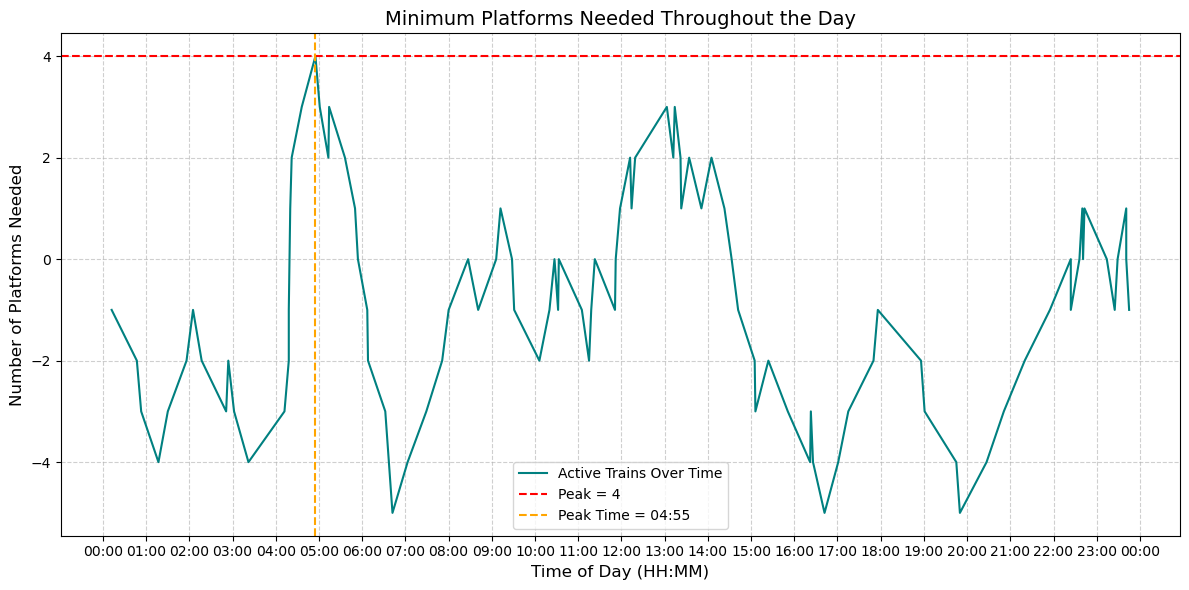

In [ ]:
import pandas as pd
import random
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import datetime, timedelta

# STEP 1: Generate Random Train Data

n = 50  # number of trains
arrivals = []
departures = []
train_ids = [f"T{i+1}" for i in range(n)]  # Train IDs like T1, T2, ...

for _ in range(n):
    # Generate random arrival time
    arr_hour = random.randint(0, 23)
    arr_min = random.randint(0, 59)
    arr_time = f"{arr_hour:02d}:{arr_min:02d}"

    # Generate random departure (15–180 minutes later)
    duration = random.randint(15, 180)
    arr_dt = datetime.strptime(arr_time, "%H:%M")
    dep_dt = arr_dt + timedelta(minutes=duration)
    dep_time = dep_dt.strftime("%H:%M")

    arrivals.append(arr_time)
    departures.append(dep_time)

# Create dataframe
df = pd.DataFrame({
    "Train_ID": train_ids,
    "Arrival": arrivals,
    "Departure": departures
})

# Convert to datetime for sorting and calculations
df["Arrival_dt"] = pd.to_datetime(df["Arrival"], format="%H:%M")
df["Departure_dt"] = pd.to_datetime(df["Departure"], format="%H:%M")

# Sort by arrival time
df = df.sort_values(by="Arrival_dt").reset_index(drop=True)

print("✅ Sample Train Schedule (Sorted by Arrival):")
print(df[["Train_ID", "Arrival", "Departure"]].head(10).to_string(index=False))

# STEP 2: Calculate Minimum Platforms
arrivals = sorted(df["Arrival_dt"].tolist())
departures = sorted(df["Departure_dt"].tolist())
n = len(arrivals)

i = j = 0
platforms_needed = 0
active_counts = []
times = []

while i < n and j < n:
    if arrivals[i] <= departures[j]:
        platforms_needed += 1
        times.append(arrivals[i])
        active_counts.append(platforms_needed)
        i += 1
    else:
        platforms_needed -= 1
        times.append(departures[j])
        active_counts.append(platforms_needed)
        j += 1

# Calculate results
min_plat = max(active_counts)
peak_index = active_counts.index(min_plat)
peak_time = times[peak_index].strftime("%H:%M")

print("\n🚉 Minimum Platforms Required:", min_plat)
print(f"⏰ Peak concurrency: {min_plat} trains at {peak_time}")

# STEP 3: Visualization
plt.figure(figsize=(12,6))
plt.plot(times, active_counts, color='teal', label="Active Trains Over Time")
plt.axhline(y=min_plat, color='red', linestyle='--', label=f"Peak = {min_plat}")
plt.axvline(x=times[peak_index], color='orange', linestyle='--', label=f"Peak Time = {peak_time}")

plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
plt.gca().xaxis.set_major_locator(mdates.HourLocator(interval=1))

plt.title("Minimum Platforms Needed Throughout the Day", fontsize=14)
plt.xlabel("Time of Day (HH:MM)", fontsize=12)
plt.ylabel("Number of Platforms Needed", fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

## CO-2: Recurrence Relation

In [ ]:
def recurrence_explanation():
    return "P(n) = max(P(n-1), Overlap(arrival_n, departures))"

print("Recurrence Relation:")
print(recurrence_explanation())

Recurrence Relation:
P(n) = max(P(n-1), Overlap(arrival_n, departures))


## CO-3: Greedy Approach Explanation

In [ ]:
def greedy_explanation():
    return (
        "The algorithm uses a greedy strategy:\n"
        "Always allocate the earliest available platform by sorting arrivals and departures.\n"
        "This ensures minimum waiting time and optimal usage of platforms."
    )

print("Greedy Explanation:")
print(greedy_explanation())

Greedy Explanation:
The algorithm uses a greedy strategy:
Always allocate the earliest available platform by sorting arrivals and departures.
This ensures minimum waiting time and optimal usage of platforms.


## CO-4: String Matching for Train IDs

In [ ]:
def search_train(train_ids, pattern):
    """Return train IDs matching the given regex pattern"""
    return [tid for tid in train_ids if re.search(pattern, tid)]

# Example search
matches = search_train(df["Train_ID"].tolist(), r"T[5-9]")

print("Train ID Search Example (pattern = 'T[5-9]'):")
print(matches[:10])

Train ID Search Example (pattern = 'T[5-9]'):
['T9', 'T6', 'T7', 'T50', 'T5', 'T8']


## CO-5: Problem Class & Optimality Discussion

In [ ]:
def problem_class():
    return (
        "Problem Class: P (Polynomial Time)\n"
        "The Greedy solution is optimal because once arrival/departure times are sorted, "
        "decisions are locally optimal and lead to a globally optimal solution."
    )

print(problem_class())

Problem Class: P (Polynomial Time)
The Greedy solution is optimal because once arrival/departure times are sorted, decisions are locally optimal and lead to a globally optimal solution.


## CO-6: Graph Algorithm for Dependency Handling

In [ ]:
def topological_sort(graph):
    indegree = {u: 0 for u in graph}
    for u in graph:
        for v in graph[u]:
            indegree[v] += 1

    queue = deque([u for u in indegree if indegree[u] == 0])
    topo_order = []

    while queue:
        u = queue.popleft()
        topo_order.append(u)
        for v in graph[u]:
            indegree[v] -= 1
            if indegree[v] == 0:
                queue.append(v)
    return topo_order


graph = {
    "T1": ["T3"],
    "T2": ["T4"],
    "T3": [],
    "T4": []
}

topo_order = topological_sort(graph)
print("Topological Order (Dependency Scheduling):", topo_order)

Topological Order (Dependency Scheduling): ['T1', 'T2', 'T3', 'T4']


## Summary and Sample Dataset Output

In [ ]:
print(" Execution Complete for All COs (CO-1 to CO-6)")
print("\nSample Dataset Preview:")
df.head(10)

 Execution Complete for All COs (CO-1 to CO-6)

Sample Dataset Preview:


,Train_ID,Arrival,Departure,Arrival_dt,Departure_dt
0,T30,01:30,03:22,1900-01-01 01:30:00,1900-01-01 03:22:00
1,T35,01:56,03:02,1900-01-01 01:56:00,1900-01-01 03:02:00
2,T49,02:05,02:51,1900-01-01 02:05:00,1900-01-01 02:51:00
3,T21,02:54,05:54,1900-01-01 02:54:00,1900-01-01 05:54:00
4,T15,04:12,06:42,1900-01-01 04:12:00,1900-01-01 06:42:00
5,T23,04:18,06:07,1900-01-01 04:18:00,1900-01-01 06:07:00
6,T40,04:18,05:36,1900-01-01 04:18:00,1900-01-01 05:36:00
7,T37,04:19,05:13,1900-01-01 04:19:00,1900-01-01 05:13:00
8,T29,04:20,05:50,1900-01-01 04:20:00,1900-01-01 05:50:00
9,T45,04:22,05:01,1900-01-01 04:22:00,1900-01-01 05:01:00
